In [ ]:
    import matplotlib.pyplot as plt
    import seaborn as sns
    import matplotlib as mpl
    import matplotlib.pylab as pylab
    import numpy as np
    %matplotlib inline
    from nltk.tokenize import sent_tokenize, word_tokenize
    import warnings
    warnings.filterwarnings(action = 'ignore')
    import gensim
    from gensim.models import Word2Vec
    import re
    import bs4 as bs
    import urllib.request 
    import nltk

In [104]:
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\mukta\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mukta\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [105]:
import urllib.request
import bs4 as bs

sentences="""Alice 23 opened the door and found that it led into a small 90
passage, not much larger than a rat-hole: she knelt down and
looked along the passage into the loveliest garden you ever saw.
How she longed to get out of that dark hall, and wander about
among those beds of bright flowers and those cool fountains, but
she could not even get her head through the doorway; `and even if
my head would go through,' (thought) $poor Alice, `it would be of
very little use without my shoulders. Oh, how I wish
I could shut up like a telescope! I think I could, if I only
know how to begin.' For, you see, so many out-of-the-way things
had happened lately, that Alice had begun to think that very few
things indeed were really impossible.
"""

In [106]:
sentences = re.sub('[^A-Za-z0-9]+', ' ', sentences)
sentences = re.sub(r'(?:^| )\w(?:$| )', ' ', sentences).strip()
print(sentences)

Alice 23 opened the door and found that it led into small 90 passage not much larger than rat hole she knelt down and looked along the passage into the loveliest garden you ever saw How she longed to get out of that dark hall and wander about among those beds of bright flowers and those cool fountains but she could not even get her head through the doorway and even if my head would go through thought poor Alice it would be of very little use without my shoulders Oh how wish could shut up like telescope think could if only know how to begin For you see so many out of the way things had happened lately that Alice had begun to think that very few things indeed were really impossible


In [107]:
sentences = re.sub('[^A-Za-z]+', ' ', sentences)

sentences = re.sub(r'(?:^| )\w(?:$| )', ' ', sentences).strip()

sentences = sentences.lower()

all_sent=nltk.sent_tokenize(sentences)
all_words=[nltk.word_tokenize(sent) for sent in all_sent]

from nltk.corpus import stopwords
for i in range(len(all_words)):
  all_words[i]=[w for w in all_words[i] if w not in stopwords.words('english')]
data =all_words
data1=data[0]

In [108]:
model1 = gensim.models.Word2Vec(data, min_count = 1,vector_size = 52, window = 5)

In [109]:
vocabulary = model1.wv.key_to_index
print(vocabulary)

{'could': 0, 'alice': 1, 'things': 2, 'think': 3, 'would': 4, 'head': 5, 'even': 6, 'get': 7, 'passage': 8, 'impossible': 9, 'really': 10, 'indeed': 11, 'begun': 12, 'lately': 13, 'happened': 14, 'way': 15, 'many': 16, 'see': 17, 'begin': 18, 'know': 19, 'telescope': 20, 'like': 21, 'shut': 22, 'wish': 23, 'oh': 24, 'shoulders': 25, 'without': 26, 'use': 27, 'little': 28, 'poor': 29, 'thought': 30, 'go': 31, 'doorway': 32, 'fountains': 33, 'cool': 34, 'flowers': 35, 'bright': 36, 'beds': 37, 'among': 38, 'wander': 39, 'hall': 40, 'dark': 41, 'longed': 42, 'saw': 43, 'ever': 44, 'garden': 45, 'loveliest': 46, 'along': 47, 'looked': 48, 'knelt': 49, 'hole': 50, 'rat': 51, 'larger': 52, 'much': 53, 'small': 54, 'led': 55, 'found': 56, 'door': 57, 'opened': 58}


In [110]:
wrd='along'
#wrd=['subset','machine', 'learning','closely','related']
v1=model1.wv[wrd]
similar_words=model1.wv.most_similar(wrd)
for x in similar_words:
  print(x)

('looked', 0.31171876192092896)
('use', 0.2966703176498413)
('thought', 0.25894615054130554)
('things', 0.24750450253486633)
('garden', 0.2334156185388565)
('head', 0.23284168541431427)
('without', 0.19903376698493958)
('even', 0.1601371318101883)
('cool', 0.15985573828220367)
('much', 0.1595705896615982)


In [111]:
print(data1)

dat = []

for i in range(2, len(data1) - 2):
    context = [data1[i - 2], data1[i - 1], data1[i + 1], data1[i + 2]]
    target = data1[i]
    dat.append((context, target))

print(dat[:5])

if len(dat) > 1:
    print(dat[1][0])
else:
    print("Not enough data to create the second context-target pair.")

['alice', 'opened', 'door', 'found', 'led', 'small', 'passage', 'much', 'larger', 'rat', 'hole', 'knelt', 'looked', 'along', 'passage', 'loveliest', 'garden', 'ever', 'saw', 'longed', 'get', 'dark', 'hall', 'wander', 'among', 'beds', 'bright', 'flowers', 'cool', 'fountains', 'could', 'even', 'get', 'head', 'doorway', 'even', 'head', 'would', 'go', 'thought', 'poor', 'alice', 'would', 'little', 'use', 'without', 'shoulders', 'oh', 'wish', 'could', 'shut', 'like', 'telescope', 'think', 'could', 'know', 'begin', 'see', 'many', 'way', 'things', 'happened', 'lately', 'alice', 'begun', 'think', 'things', 'indeed', 'really', 'impossible']
[(['alice', 'opened', 'found', 'led'], 'door'), (['opened', 'door', 'led', 'small'], 'found'), (['door', 'found', 'small', 'passage'], 'led'), (['found', 'led', 'passage', 'much'], 'small'), (['led', 'small', 'much', 'larger'], 'passage')]
['opened', 'door', 'led', 'small']


In [ ]:
for val in dat:
    print(val[0], val[1])

i = 3

if len(dat) > i:
    print('\n OUTPUT')
    print(dat[i])
    
    print(model1.predict_output_word(dat[i][0]))
else:
    print("Index 3 does not exist in dat")

['alice', 'opened', 'found', 'led'] door
['opened', 'door', 'led', 'small'] found
['door', 'found', 'small', 'passage'] led
['found', 'led', 'passage', 'much'] small
['led', 'small', 'much', 'larger'] passage
['small', 'passage', 'larger', 'rat'] much
['passage', 'much', 'rat', 'hole'] larger
['much', 'larger', 'hole', 'knelt'] rat
['larger', 'rat', 'knelt', 'looked'] hole
['rat', 'hole', 'looked', 'along'] knelt
['hole', 'knelt', 'along', 'passage'] looked
['knelt', 'looked', 'passage', 'loveliest'] along
['looked', 'along', 'loveliest', 'garden'] passage
['along', 'passage', 'garden', 'ever'] loveliest
['passage', 'loveliest', 'ever', 'saw'] garden
['loveliest', 'garden', 'saw', 'longed'] ever
['garden', 'ever', 'longed', 'get'] saw
['ever', 'saw', 'get', 'dark'] longed
['saw', 'longed', 'dark', 'hall'] get
['longed', 'get', 'hall', 'wander'] dark
['get', 'dark', 'wander', 'among'] hall
['dark', 'hall', 'among', 'beds'] wander
['hall', 'wander', 'beds', 'bright'] among
['wander', 'am

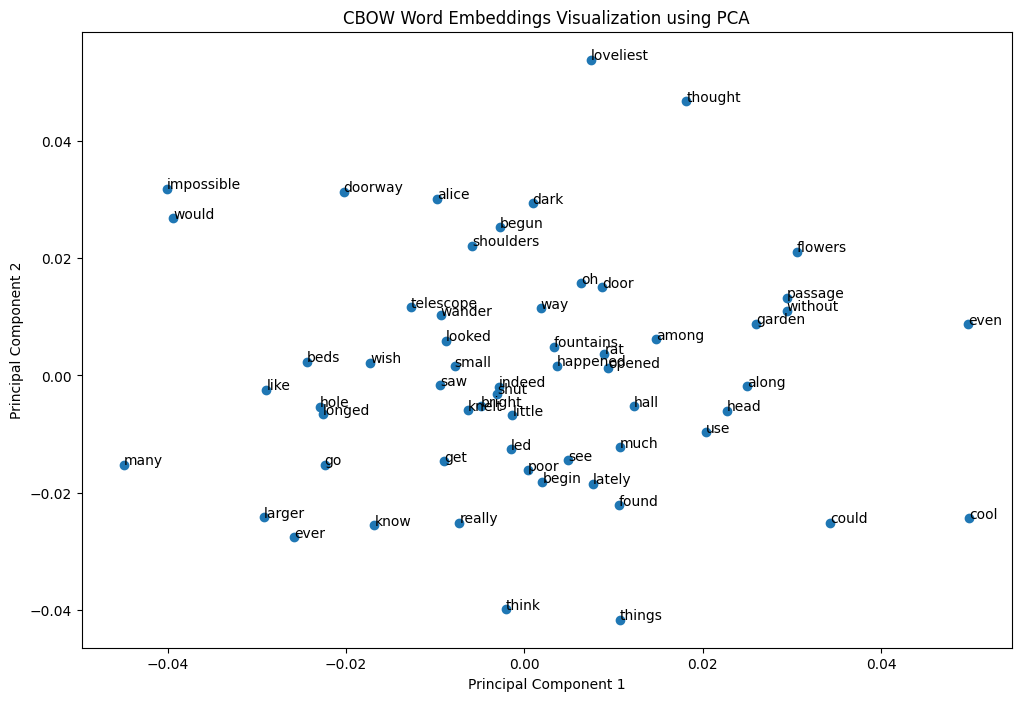

In [113]:
from sklearn.decomposition import PCA
from matplotlib import pyplot
words = model1.wv.index_to_key
X = model1.wv[words]
pca = PCA(n_components=2)
result = pca.fit_transform(X)
pyplot.figure(figsize=(12, 8))
pyplot.scatter(result[:, 0], result[:, 1])
for i, word in enumerate(words):
    pyplot.annotate(
        word,
        xy=(result[i, 0], result[i, 1])
    )

pyplot.xlabel("Principal Component 1")
pyplot.ylabel("Principal Component 2")
pyplot.title("CBOW Word Embeddings Visualization using PCA")
pyplot.show()